---
course_code: 02BMSBI24365
course_title: AI and ML in Bioinformatics
unit: Unit 3 — Deep Learning for Biological Data & Applied Lab Practicals
document_type: Interactive Laboratory Practical Notebook
ai_tier: "Tier 3: AI Collaboration (Disclosed)"
---

# Lab Exercise 01: End-to-End Binary Classification Pipeline for Gene Expression

**Course Code:** `02BMSBI24365` — AI & ML in Bioinformatics
**Target Audience:** M.Sc. Bioinformatics (Semester III)
**Primary Dataset:** TCGA-BRCA PanCancer Atlas Transcriptomic Cohort ($n = 670, p = 60$)
**Target Variable:** Intrinsic Subtype (`0 = BRCA_LumA`, `1 = BRCA_Basal`)
**Assigned AI Tier:** Tier 3: AI Collaboration (Disclosed)

---

### Clinical Problem Formulation
Breast cancer encompasses distinct transcriptomic entities with divergent clinical trajectories:
* **Luminal A (`BRCA_LumA`):** Estrogen receptor positive (*ESR1*, *PGR*, *GATA3*, *FOXA1*); favorable prognosis; responsive to endocrine therapy.
* **Basal-like (`BRCA_Basal`):** Hormone receptor negative (TNBC-like); driven by basal keratins (*KRT5*, *KRT14*) and proliferation markers (*MKI67*); aggressive clinical course requiring cytotoxic chemotherapy.

**The Clinical Cost Asymmetry:**
Missing an aggressive Basal tumor as Luminal A (**False Negative**) delays chemotherapy and endangers patient survival. Our clinical objective is to maximize **Sensitivity (Recall)** and tune decision thresholds ($	au$) to eliminate False Negatives.

## 1. Computational Environment & Reproducible Setup

We initialize random seeds for reproducibility and configure clean plotting defaults.

In [1]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix
)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Configure reproducibility and clean plotting style
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid", font_scale=1.0)
warnings.filterwarnings('ignore')

print(f"[✓] Environment ready. TensorFlow {tf.__version__}, Scikit-Learn initialized.")

[✓] Environment ready. TensorFlow 2.21.0, Scikit-Learn initialized.


## 2. Data Ingestion & Quality Control Audit

We load the curated PAM50 breast cancer gene expression dataset (`tcga_brca_expression.csv`), which contains $n = 670$ primary tumor patient biopsies across $p = 60$ curated genes. The target labels represent intrinsic subtypes: Luminal A (`target = 0`, $n = 499$) and Basal-like (`target = 1`, $n = 171$).

> **Student Note:** To run this pipeline on your own custom dataset or project milestone, simply replace `data_path` with the path to your own CSV file.

In [2]:
# Load gene expression cohort (replace with your own CSV file for custom analysis)
data_path = "data/tcga_brca_expression.csv"
if not os.path.exists(data_path):
    data_path = "labs/lab_01_binary_classification_pipeline/data/tcga_brca_expression.csv"

df = pd.read_csv(data_path)

# Separate clinical metadata from genomic features
meta_cols = ["sample_id", "patient_id", "subtype", "target"]
gene_cols = [c for c in df.columns if c not in meta_cols]

print(f"[✓] Cohort loaded: {df.shape[0]} samples × {len(gene_cols)} genes. Missing values: {df.isnull().sum().sum()}")
print(df["subtype"].value_counts())
df.head(3)

[✓] Cohort loaded: 670 samples × 60 genes. Missing values: 0
subtype
BRCA_LumA     499
BRCA_Basal    171
Name: count, dtype: int64


,sample_id,patient_id,subtype,target,ANLN,AR,ATM,BAG1,BCL2,BIRC5,...,PTTG1,RB1,RRM2,SFRP1,SLC39A6,TMEM45B,TP53,TYMS,UBE2C,UBE2T
0,TCGA-3C-AAAU-01,TCGA-3C-AAAU,BRCA_LumA,0,828.215,1097.740,875.433,1890.57,2315.76,390.798,...,383.605,496.309,1477.210,473.217,90765.90,2.4126,1385.53,493.114,555.590,318.465
1,TCGA-3C-AALK-01,TCGA-3C-AALK,BRCA_LumA,0,631.775,503.930,842.367,1651.16,2172.11,522.019,...,311.957,1000.000,909.392,1236.660,19032.70,532.4780,1418.29,724.692,496.897,373.190
2,TCGA-4H-AAAK-01,TCGA-4H-AAAK,BRCA_LumA,0,359.575,673.617,420.000,2154.50,1575.32,202.962,...,257.872,959.574,384.255,1531.910,3834.89,385.1060,1484.26,675.723,322.128,192.340


## 3. Exploratory Data Analysis (EDA) & PCA

We inspect the expression of key hallmark genes (*ESR1*, *GATA3*, *KRT5*, *MKI67*) and project the 60-gene space into 2D using Principal Component Analysis (PCA).

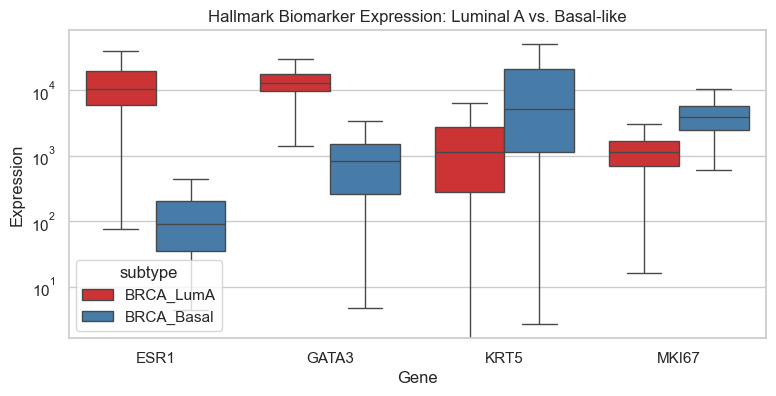

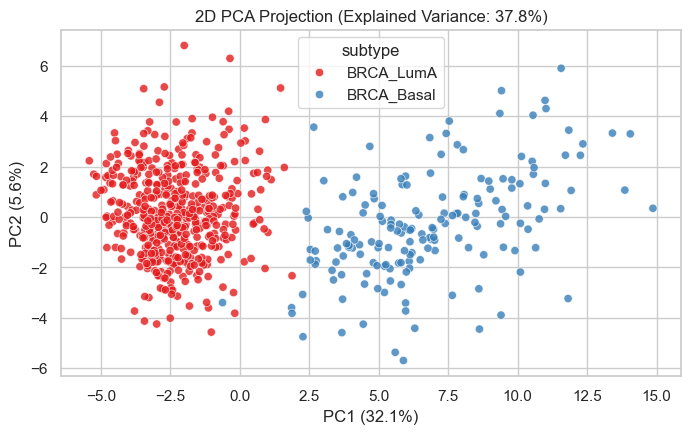

In [3]:
# 1. Boxplot of hallmark luminal vs. basal biomarkers
hallmarks = ['ESR1', 'GATA3', 'KRT5', 'MKI67']
melted_df = pd.melt(df, id_vars=['subtype'], value_vars=hallmarks, var_name='Gene', value_name='Expression')

plt.figure(figsize=(9, 4))
sns.boxplot(data=melted_df, x='Gene', y='Expression', hue='subtype', palette='Set1', showfliers=False)
plt.title("Hallmark Biomarker Expression: Luminal A vs. Basal-like")
plt.yscale('log')
plt.show()

# 2. Unsupervised 2D PCA projection
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(StandardScaler().fit_transform(df[gene_cols]))

plt.figure(figsize=(8, 4.5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['subtype'], palette='Set1', alpha=0.8)
plt.title(f"2D PCA Projection (Explained Variance: {pca.explained_variance_ratio_.sum()*100:.1f}%)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.show()

## 4. Leak-Free Preprocessing & Stratified Train/Test Split

**Zero Data Leakage Rule:** All transformations (e.g. `StandardScaler`) must be fitted *strictly* on training data and applied to the test data to prevent data snooping.

In [4]:
# Extract features and target
X = df[gene_cols].values
y = df['target'].values

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Fit scaler strictly on training partition
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"[✓] Training samples: {X_train.shape[0]} (LumA: {(y_train==0).sum()}, Basal: {(y_train==1).sum()})")
print(f"[✓] Test samples:     {X_test.shape[0]} (LumA: {(y_test==0).sum()}, Basal: {(y_test==1).sum()})")

[✓] Training samples: 536 (LumA: 399, Basal: 137)
[✓] Test samples:     134 (LumA: 100, Basal: 34)


## 5. Statistical Biomarker Ranking (ANOVA F-Test)

We rank the top discriminative genes on training data using univariate ANOVA F-statistics.

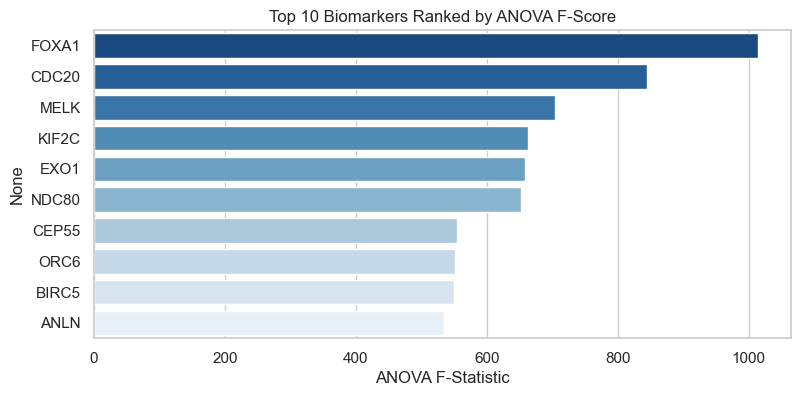

In [5]:
# Compute ANOVA F-scores on training data
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train_scaled, y_train)

f_scores = pd.Series(selector.scores_, index=gene_cols).sort_values(ascending=False)

plt.figure(figsize=(9, 4))
sns.barplot(x=f_scores.head(10).values, y=f_scores.head(10).index, palette='Blues_r')
plt.title("Top 10 Biomarkers Ranked by ANOVA F-Score")
plt.xlabel("ANOVA F-Statistic")
plt.show()

### Evaluation Helper Function
We define a reusable function to compute standard clinical metrics across models.

In [6]:
def evaluate_model(y_true, y_prob, threshold=0.50):
    y_pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Sensitivity (Recall)': recall_score(y_true, y_pred, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'F1-Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'FN': fn,
        'FP': fp
    }

## 6. Model 1: L2-Regularized Logistic Regression

Logistic regression serves as our interpretable linear baseline. We train the model, evaluate predictions on the held-out test set, plot its confusion matrix, and extract gene Odds Ratios ($	ext{OR} = e^{w_j}$).

=== Logistic Regression Test Metrics (τ = 0.50) ===
    - Accuracy              : 0.9925
    - Sensitivity (Recall)  : 0.9706
    - Specificity           : 1.0000
    - Precision             : 1.0000
    - F1-Score              : 0.9851
    - ROC-AUC               : 0.9997
    - FN                    : 1
    - FP                    : 0


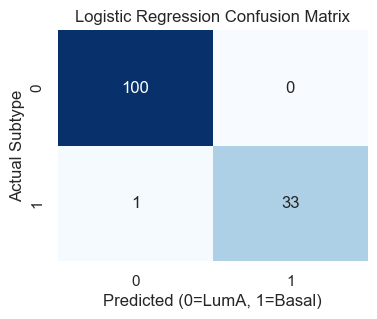


Top 5 Risk Biomarkers (Basal):
 FOXC1    1.809621
SFRP1    1.548264
CDH3     1.547403
CDK6     1.485378
CEP55    1.483132
dtype: float64

Top 5 Protective Biomarkers (LumA):
 MLPH      0.632481
GPR160    0.616445
FOXA1     0.558806
GATA3     0.538813
CXXC5     0.496866
dtype: float64


In [7]:
# 1. Train Logistic Regression
lr_model = LogisticRegression(penalty='l2', C=1.0, random_state=SEED)
lr_model.fit(X_train_scaled, y_train)

# 2. Evaluate on held-out test set
p_test_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
lr_metrics = evaluate_model(y_test, p_test_lr)

print("=== Logistic Regression Test Metrics (τ = 0.50) ===")
for k, v in lr_metrics.items():
    print(f"    - {k:<22}: {v:.4f}" if isinstance(v, float) else f"    - {k:<22}: {v}")

# 3. Confusion Matrix plot
cm_lr = confusion_matrix(y_test, (p_test_lr >= 0.50).astype(int))
plt.figure(figsize=(4, 3))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted (0=LumA, 1=Basal)")
plt.ylabel("Actual Subtype")
plt.show()

# 4. Top gene Odds Ratios (OR = exp(weight))
lr_odds = pd.Series(np.exp(lr_model.coef_[0]), index=gene_cols).sort_values(ascending=False)
print("\nTop 5 Risk Biomarkers (Basal):\n", lr_odds.head(5))
print("\nTop 5 Protective Biomarkers (LumA):\n", lr_odds.tail(5))

## 7. Model 2: Random Forest Classifier

Random Forest is a non-linear ensemble of 100 bagged decision trees capable of capturing biological interactions. We train the ensemble, evaluate held-out test performance, plot its confusion matrix, and inspect Gini Feature Importances.

=== Random Forest Test Metrics (τ = 0.50) ===
    - Accuracy              : 1.0000
    - Sensitivity (Recall)  : 1.0000
    - Specificity           : 1.0000
    - Precision             : 1.0000
    - F1-Score              : 1.0000
    - ROC-AUC               : 1.0000
    - FN                    : 0
    - FP                    : 0


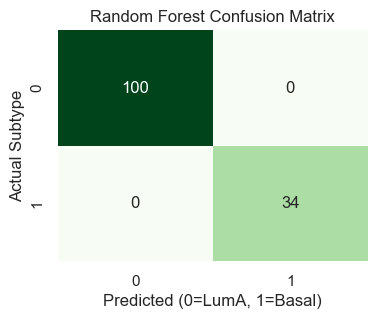

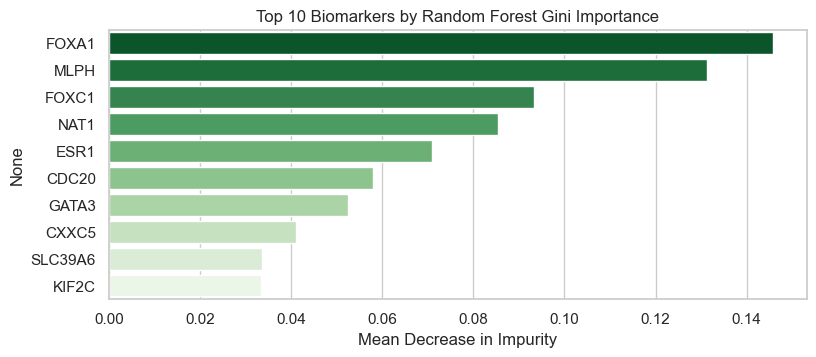

In [8]:
# 1. Train Random Forest (100 Trees)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED)
rf_model.fit(X_train_scaled, y_train)

# 2. Evaluate on held-out test set
p_test_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
rf_metrics = evaluate_model(y_test, p_test_rf)

print("=== Random Forest Test Metrics (τ = 0.50) ===")
for k, v in rf_metrics.items():
    print(f"    - {k:<22}: {v:.4f}" if isinstance(v, float) else f"    - {k:<22}: {v}")

# 3. Confusion Matrix plot
cm_rf = confusion_matrix(y_test, (p_test_rf >= 0.50).astype(int))
plt.figure(figsize=(4, 3))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted (0=LumA, 1=Basal)")
plt.ylabel("Actual Subtype")
plt.show()

# 4. Gini Feature Importance
rf_importance = pd.Series(rf_model.feature_importances_, index=gene_cols).sort_values(ascending=False)
plt.figure(figsize=(9, 3.5))
sns.barplot(x=rf_importance.head(10).values, y=rf_importance.head(10).index, palette='Greens_r')
plt.title("Top 10 Biomarkers by Random Forest Gini Importance")
plt.xlabel("Mean Decrease in Impurity")
plt.show()

## 8. Model 3: Keras Artificial Neural Network (MLP)

We construct a multi-layer perceptron (MLP) using Keras with Dropout layers ($0.30, 0.20$) to prevent memorization in $p \gg n$ regimes. We train for 50 epochs, plot the training loss curve, evaluate on the test set, and explore clinical threshold tuning ($	au$) to eliminate False Negatives.

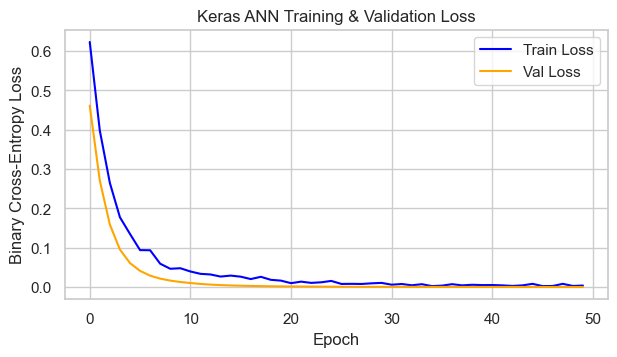

=== Keras ANN Test Metrics (τ = 0.50) ===
    - Accuracy              : 0.9851
    - Sensitivity (Recall)  : 0.9412
    - Specificity           : 1.0000
    - Precision             : 1.0000
    - F1-Score              : 0.9697
    - ROC-AUC               : 0.9965
    - FN                    : 2
    - FP                    : 0


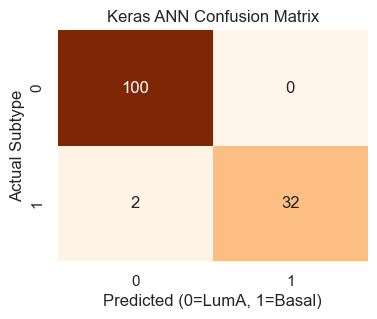

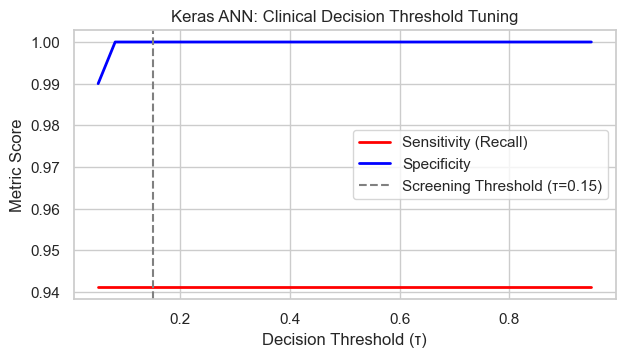

In [9]:
# 1. Build Keras Sequential Architecture
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

ann_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],), name="Input_Genes"),
    layers.Dense(32, activation='relu', name="Hidden_1"),
    layers.Dropout(0.30, name="Dropout_1"),
    layers.Dense(16, activation='relu', name="Hidden_2"),
    layers.Dropout(0.20, name="Dropout_2"),
    layers.Dense(1, activation='sigmoid', name="Output_Basal_Prob")
])

ann_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

# 2. Train over 50 epochs
history = ann_model.fit(
    X_train_scaled, y_train,
    validation_split=0.15,
    epochs=50,
    batch_size=32,
    verbose=0
)

# 3. Simple Training vs. Validation Loss plot
plt.figure(figsize=(7, 3.5))
plt.plot(history.history['loss'], label='Train Loss', color='blue')
plt.plot(history.history['val_loss'], label='Val Loss', color='orange')
plt.title("Keras ANN Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.show()

# 4. Evaluate on held-out test set
p_test_ann = ann_model.predict(X_test_scaled, verbose=0).flatten()
ann_metrics = evaluate_model(y_test, p_test_ann)

print("=== Keras ANN Test Metrics (τ = 0.50) ===")
for k, v in ann_metrics.items():
    print(f"    - {k:<22}: {v:.4f}" if isinstance(v, float) else f"    - {k:<22}: {v}")

# 5. Confusion Matrix plot
cm_ann = confusion_matrix(y_test, (p_test_ann >= 0.50).astype(int))
plt.figure(figsize=(4, 3))
sns.heatmap(cm_ann, annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.title("Keras ANN Confusion Matrix")
plt.xlabel("Predicted (0=LumA, 1=Basal)")
plt.ylabel("Actual Subtype")
plt.show()

# 6. Clinical Decision Threshold Tuning (Sweeping τ)
thresholds = np.linspace(0.05, 0.95, 30)
sens_list = [evaluate_model(y_test, p_test_ann, threshold=t)['Sensitivity (Recall)'] for t in thresholds]
spec_list = [evaluate_model(y_test, p_test_ann, threshold=t)['Specificity'] for t in thresholds]

plt.figure(figsize=(7, 3.5))
plt.plot(thresholds, sens_list, label='Sensitivity (Recall)', color='red', lw=2)
plt.plot(thresholds, spec_list, label='Specificity', color='blue', lw=2)
plt.axvline(0.15, color='gray', linestyle='--', label='Screening Threshold (τ=0.15)')
plt.title("Keras ANN: Clinical Decision Threshold Tuning")
plt.xlabel("Decision Threshold (τ)")
plt.ylabel("Metric Score")
plt.legend()
plt.show()

## 9. Multi-Model Benchmark Comparison

We compare all three models side-by-side across diagnostic metrics and overlay their Receiver Operating Characteristic (ROC) curves.

,Model,Accuracy,Sensitivity (Recall),Specificity,Precision,F1-Score,ROC-AUC,FN,FP
0,Logistic Regression,0.992537,0.970588,1.0,1.0,0.985075,0.999706,1,0
1,Random Forest,1.000000,1.000000,1.0,1.0,1.000000,1.000000,0,0
2,Keras ANN,0.985075,0.941176,1.0,1.0,0.969697,0.996471,2,0


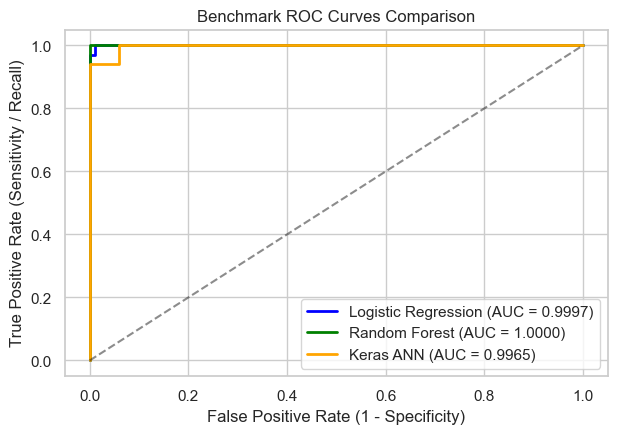

In [10]:
# 1. Side-by-side benchmark comparison table
benchmark_df = pd.DataFrame([
    {'Model': 'Logistic Regression', **lr_metrics},
    {'Model': 'Random Forest', **rf_metrics},
    {'Model': 'Keras ANN', **ann_metrics}
])

display(benchmark_df)

# 2. Combined ROC Curves overlay
plt.figure(figsize=(7, 4.5))
for name, probs, col in [('Logistic Regression', p_test_lr, 'blue'),
                         ('Random Forest', p_test_rf, 'green'),
                         ('Keras ANN', p_test_ann, 'orange')]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.4f})", color=col, lw=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.title("Benchmark ROC Curves Comparison")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.legend(loc="lower right")
plt.show()

## 10. Biological Synthesis & Student Extension

### Biological Insights
1. **Luminal Drivers (*ESR1*, *GATA3*, *FOXA1*):** Overwhelmingly protective against the Basal phenotype ($	ext{OR} < 1$). High expression signifies hormone-dependent cancer susceptible to endocrine targeting.
2. **Proliferation Drivers (*CDC20*, *MELK*, *KIF2C*, *EXO1*, *MKI67*):** Top ANOVA and Random Forest importance drivers, capturing the heightened mitotic activity of aggressive Basal tumors.

---

### Student Challenge: Minimal Point-of-Care 5-Gene Panel
Evaluate whether a minimal 5-gene point-of-care PCR diagnostic panel (*FOXA1*, *CDC20*, *MELK*, *KIF2C*, *EXO1*) can match the performance of the full 60-gene transcriptome.

In [11]:
# Minimal 5-gene panel evaluation
panel_genes = ['FOXA1', 'CDC20', 'MELK', 'KIF2C', 'EXO1']
panel_indices = [gene_cols.index(g) for g in panel_genes]

# Train Logistic Regression on minimal 5-gene panel
lr_panel = LogisticRegression(random_state=SEED)
lr_panel.fit(X_train_scaled[:, panel_indices], y_train)

p_test_panel = lr_panel.predict_proba(X_test_scaled[:, panel_indices])[:, 1]
panel_metrics = evaluate_model(y_test, p_test_panel)

print("=== Minimal 5-Gene Panel vs. Full 60-Gene Model ===")
panel_comp = pd.DataFrame([
    {'Panel': 'Full 60-Gene LR', **lr_metrics},
    {'Panel': 'Minimal 5-Gene LR', **panel_metrics}
])
display(panel_comp)

=== Minimal 5-Gene Panel vs. Full 60-Gene Model ===


,Panel,Accuracy,Sensitivity (Recall),Specificity,Precision,F1-Score,ROC-AUC,FN,FP
0,Full 60-Gene LR,0.992537,0.970588,1.00,1.000000,0.985075,0.999706,1,0
1,Minimal 5-Gene LR,0.985075,0.970588,0.99,0.970588,0.970588,0.999118,1,1
